# Low Carbon London: descriptive analysis (arms N and D)

Low Carbon London (UK Data Service SN 7857) supplies the **host household load** for both
synthetic datasets in this thesis:

- **Arm N** (standard tariff) hosts the heat pumps and EV chargers used for training.
- **Arm D** (dynamic time-of-use tariff during 2013) hosts the held-out heat-pump transfer set.

This notebook describes both arms. It produces two tables (data breakdown; household
characteristics) and six figures.

**Data** (`Data/LCL/csv/data_collection/data_tables/`):
- `consumption_n.csv` and `consumption_d.csv`: half-hourly kWh, one column per household.
- `survey_answers.csv` and `survey_questions.csv`: the appliance survey.

**Timestamps.** `GMT` marks the *end* of each half-hour. Every date and time-of-day below is
taken from the period **start** (`GMT − 30 min`).

**Population.** Except for the coverage figure and the first rows of Table LCL_T1, every
statistic uses the households that pass the quality filters (section 2). These are the same filters
the heat-pump linkage applies, so the figures describe the population that enters the
synthetic datasets.

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
DATA_DIR = NB_DIR / "Data" / "LCL" / "csv" / "data_collection" / "data_tables"
CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (CACHE_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

CSV = {"N": DATA_DIR / "consumption_n.csv", "D": DATA_DIR / "consumption_d.csv"}
SURVEY_ANSWERS = DATA_DIR / "survey_answers.csv"
SURVEY_QUESTIONS = DATA_DIR / "survey_questions.csv"
for p in [*CSV.values(), SURVEY_ANSWERS, SURVEY_QUESTIONS]:
    assert p.exists(), f"missing expected data file: {p}"

# Seasonal statistics use one calendar year. 2013 is the only complete year (the release runs
# 2011-11-23 to 2014-02-27) and the only year arm D was on the dynamic tariff.
ANALYSIS_YEAR = 2013

# Quality filters, identical to the heat-pump linkage (LCL_EoH_join_v6).
COMPLETE_MIN_SLOTS = 46   # a complete day has >= 46 of 48 half-hours
MIN_COMPLETE_DAYS = 200   # a usable household has >= 200 complete days
MIN_MEAN_KWH = 0.05       # below this mean daily kWh a meter reads as vacant or faulty

# Winter/summer ratio: meteorological seasons within ANALYSIS_YEAR.
WINTER_MONTHS, SUMMER_MONTHS = [12, 1, 2], [6, 7, 8]
MIN_SEASON_DAYS = 15

# EV charging check, the Metcalfe et al. (2026) rule (section 2). An event is a run of EV_MIN_RUN to EV_MAX_RUN consecutive
# half-hours, each above EV_KWH_THRESHOLD kWh (3.5 kWh in a half-hour is 7 kW). A suspected EV
# owner has EV_RATE_MIN to EV_RATE_MAX events per week, both ends included.
EV_KWH_THRESHOLD = 3.5
EV_MIN_RUN, EV_MAX_RUN = 4, 12
EV_RATE_MIN, EV_RATE_MAX = 0.5, 4.0

# Heat-map colour scale, shared with 02_eoh_analysis and with Figure HP_J3 of 04_hp_linkage_lcl_eoh,
# so the maps compare directly. Heat-pump load reaches about 1 kWh per half-hour.
HEATMAP_VMAX = 1.05

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

WINTER_COLOR, SUMMER_COLOR, ALLYEAR_COLOR = CAT["blue"], CAT["orange"], INK_SECONDARY
ARM_COLORS = {"N": CAT["blue"], "D": CAT["orange"]}
ARM_LABELS = {"N": "Arm N (standard tariff)", "D": "Arm D (dynamic time-of-use tariff)"}
HEAT_ORDER = ["Gas", "Mixed", "Electric only"]
HEAT_COLORS = {"All arm N": INK_SECONDARY, "Gas": CAT["orange"], "Mixed": CAT["violet"],
               "Electric only": CAT["blue"]}
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

SEQ_BLUE_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})


COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df


def hhmm_axis(ax, step_hours=3):
    # Label a 48-slot time-of-day x-axis; slot i spans [i, i+1) (period start).
    ticks = list(range(0, 49, step_hours * 2))
    ax.set_xticks(ticks)
    ax.set_xticklabels(["24:00" if t == 48 else f"{t // 2:02d}:{'00' if t % 2 == 0 else '30'}"
                        for t in ticks])

## 2. Data loading and quality filters

Each wide CSV is unpivoted with DuckDB to a long table `(household_id, ts, kwh)`, with the date
and time of day taken from the period start, and cached as parquet. Delete `cache/` to rebuild
from the raw CSVs.

A **complete day** has at least 46 of 48 half-hours. A household **passes the quality filters**
if it has at least 200 complete days and a mean of at least 0.05 kWh/day.

In [3]:
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("PRAGMA preserve_insertion_order=false")
con.execute("PRAGMA memory_limit='8GB'")
con.execute(f"SET temp_directory='{CACHE_DIR / 'duckdb_tmp'}'")


def build_long(csv_path: Path, out_path: Path):
    # Wide -> long via UNPIVOT, streamed straight to parquet, nulls dropped. LCL stamps each
    # reading at the end of its half-hour, so period_start is 30 minutes earlier.
    if out_path.exists():
        return
    with open(csv_path) as f:
        header = f.readline().strip().split(",")
    types = "{" + ",".join(["'GMT':'TIMESTAMP'"] + [f"'{c}':'DOUBLE'" for c in header[1:]]) + "}"
    con.execute(f"""
        COPY (
            SELECT household_id, ts, ts - INTERVAL 30 MINUTE AS period_start, kwh,
                   CAST(ts - INTERVAL 30 MINUTE AS DATE) AS date,
                   strftime(ts - INTERVAL 30 MINUTE, '%H:%M') AS hh_of_day,
                   month(ts - INTERVAL 30 MINUTE) AS month
            FROM (
                SELECT household_id, GMT AS ts, kwh
                FROM (
                    UNPIVOT (SELECT * FROM read_csv('{csv_path.as_posix()}', columns={types}, header=true))
                    ON COLUMNS(* EXCLUDE (GMT))
                    INTO NAME household_id VALUE kwh
                )
                WHERE kwh IS NOT NULL
            )
        ) TO '{out_path.as_posix()}' (FORMAT PARQUET)
    """)


EXT = {arm: CACHE_DIR / f"{arm.lower()}_ext.parquet" for arm in ("N", "D")}
for arm in ("N", "D"):
    build_long(CSV[arm], EXT[arm])
    con.execute(f"CREATE OR REPLACE VIEW {arm.lower()}_ext AS SELECT * FROM '{EXT[arm].as_posix()}'")
    print(f"arm {arm}:", con.execute(
        f"SELECT count(*), count(DISTINCT household_id), min(date), max(date) FROM {arm.lower()}_ext").fetchone())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

arm N: (126402300, 4173, datetime.date(2011, 11, 23), datetime.date(2014, 2, 27))
arm D: (31649514, 1025, datetime.date(2011, 11, 23), datetime.date(2014, 2, 27))


In [4]:
# Household-day totals for both arms.
HOUSEHOLD_DAY = CACHE_DIR / "household_day.parquet"
if not HOUSEHOLD_DAY.exists():
    con.execute(f"""
        COPY (
            SELECT 'N' AS arm, household_id, date, count(*) AS n_slots, sum(kwh) AS total_kwh FROM n_ext GROUP BY 2, 3
            UNION ALL
            SELECT 'D', household_id, date, count(*), sum(kwh) FROM d_ext GROUP BY 2, 3
        ) TO '{HOUSEHOLD_DAY.as_posix()}' (FORMAT PARQUET)
    """)
household_day = pd.read_parquet(HOUSEHOLD_DAY)
household_day["date"] = pd.to_datetime(household_day["date"])
household_day["month"] = household_day.date.dt.month
household_day["year"] = household_day.date.dt.year
complete = household_day[household_day.n_slots >= COMPLETE_MIN_SLOTS]
print(household_day.shape, "household-days;", len(complete), "complete")

(3295592, 7) household-days; 3288485 complete


In [5]:
# One row per metered household.
hh = (household_day.groupby(["arm", "household_id"]).size().rename("n_any_days").reset_index()
      .merge(complete.groupby("household_id")
                     .agg(n_complete_days=("date", "size"), mean_daily_kwh=("total_kwh", "mean"))
                     .reset_index(), on="household_id", how="left"))
hh["n_complete_days"] = hh.n_complete_days.fillna(0).astype(int)
hh["passes_filters"] = (hh.n_complete_days >= MIN_COMPLETE_DAYS) & (hh.mean_daily_kwh >= MIN_MEAN_KWH)

# ANALYSIS_YEAR statistics: annual mean daily kWh and the winter/summer ratio.
year_days = complete[complete.year == ANALYSIS_YEAR]
season = np.select([year_days.month.isin(WINTER_MONTHS), year_days.month.isin(SUMMER_MONTHS)],
                   ["winter", "summer"], "shoulder")
seasonal = (year_days.assign(season=season)
            .pivot_table(index="household_id", columns="season", values="total_kwh", aggfunc=["mean", "size"]))
seasonal.columns = [f"{stat}_{s}" for stat, s in seasonal.columns]
year_mean = year_days.groupby("household_id").total_kwh.mean().rename("mean_daily_kwh_year")
hh = (hh.merge(seasonal[["mean_winter", "mean_summer", "size_winter", "size_summer"]],
               left_on="household_id", right_index=True, how="left")
        .merge(year_mean, left_on="household_id", right_index=True, how="left"))
for c in ["size_winter", "size_summer"]:
    hh[c] = hh[c].fillna(0).astype(int)

usable_ratio = ((hh.size_winter >= MIN_SEASON_DAYS) & (hh.size_summer >= MIN_SEASON_DAYS)
                & (hh.mean_winter > MIN_MEAN_KWH) & (hh.mean_summer > MIN_MEAN_KWH))
hh["winter_summer_ratio"] = np.where(usable_ratio, hh.mean_winter / hh.mean_summer, np.nan)

print(hh.groupby("arm").agg(households=("household_id", "size"), pass_filters=("passes_filters", "sum"),
                            usable_ratio=("winter_summer_ratio", "count")))

     households  pass_filters  usable_ratio
arm                                        
D          1025          1025          1022
N          4173          4157          4019


### EV charging check: the Metcalfe et al. rule

LCL (2011 to 2014) predates most home EV charging, so its households are treated as having no
EV, and both synthetic datasets rely on that. This section checks it by applying the rule-based
screen for suspected EV owners from [Metcalfe et al. (2026)](https://doi.org/10.3386/w34709), which also serves as a test of that
rule on load known to be almost free of EV charging.

A **charging event** is a run of 4 to 12 consecutive half-hours, each above 3.5 kWh (7 kW), on
the unbroken series. A run ends at any gap in the readings, and a run longer than 12 half-hours
is not an event. Events are counted for both arms and attributed to the day they start, keeping
only events that start on a complete day.

A household's rate is **events per week = events ÷ (complete days ÷ 7)**, and the rule flags a
household as a **suspected EV owner** at 0.5 to 4 events per week, both ends included.

The rule flags very few households (below), which confirms that LCL can be treated as having no
EVs. The flagged households are taken as false positives of the rule, from other sustained loads
above 7 kW, not as EV owners. The flag is stored on the household table, so it reaches the master
table the linkages read.

In [6]:
EV_EVENTS = CACHE_DIR / "ev_events_both_arms.parquet"
if not EV_EVENTS.exists():
    con.execute(f"""
        CREATE OR REPLACE TABLE ev_events AS
        WITH allx AS (
            SELECT 'N' AS arm, household_id, date, ts, kwh FROM n_ext
            UNION ALL
            SELECT 'D', household_id, date, ts, kwh FROM d_ext),
        flagged AS (
            SELECT arm, household_id, date, ts,
                   CASE WHEN kwh > {EV_KWH_THRESHOLD} THEN 1 ELSE 0 END AS flag
            FROM allx),
        lagged AS (
            SELECT *, lag(flag) OVER w AS prev_flag, lag(ts) OVER w AS prev_ts
            FROM flagged WINDOW w AS (PARTITION BY arm, household_id ORDER BY ts)),
        blocks AS (
            SELECT *, sum(CASE WHEN prev_flag IS DISTINCT FROM flag
                                 OR (prev_ts IS NOT NULL AND ts - prev_ts != INTERVAL 30 MINUTE)
                               THEN 1 ELSE 0 END)
                      OVER (PARTITION BY arm, household_id ORDER BY ts ROWS UNBOUNDED PRECEDING) AS block_id
            FROM lagged)
        SELECT arm, household_id, min(date) AS onset_date
        FROM blocks WHERE flag = 1
        GROUP BY arm, household_id, block_id
        HAVING count(*) BETWEEN {EV_MIN_RUN} AND {EV_MAX_RUN}
    """)
    con.execute(f"""
        COPY (
            SELECT e.arm, e.household_id, count(*) AS n_ev_events
            FROM ev_events e
            JOIN '{HOUSEHOLD_DAY.as_posix()}' d
              ON d.arm = e.arm AND d.household_id = e.household_id AND d.date = e.onset_date
            WHERE d.n_slots >= {COMPLETE_MIN_SLOTS}
            GROUP BY 1, 2
        ) TO '{EV_EVENTS.as_posix()}' (FORMAT PARQUET)
    """)

hh = hh.merge(pd.read_parquet(EV_EVENTS), on=["arm", "household_id"], how="left")
hh["n_ev_events"] = hh.n_ev_events.fillna(0).astype(int)
complete_weeks = hh.n_complete_days.where(hh.n_complete_days > 0) / 7
hh["ev_events_per_week"] = hh.n_ev_events / complete_weeks
hh["suspected_ev"] = hh.ev_events_per_week.between(EV_RATE_MIN, EV_RATE_MAX)

ok = hh[hh.passes_filters]
print(ok.groupby("arm").agg(households=("household_id", "size"),
                            events=("n_ev_events", "sum"),
                            with_an_event=("n_ev_events", lambda s: int((s > 0).sum())),
                            suspected_ev=("suspected_ev", "sum")))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

     households  events  with_an_event  suspected_ev
arm                                                 
D          1025     171             14             1
N          4157    1405            100             7


## 3. Heating type and dwelling, from the appliance survey

**The question file is off by one.** The answers in column `Qn` belong to the question
*labelled* `Q(n+1)`. For example, column `Q213` holds household sizes, which is question `Q214`.
The columns used here are therefore:

| Answer column | True question |
|---|---|
| `Q235` | Accommodation: house (detached / semi-detached / terraced) |
| `Q236` | Accommodation: flat (purpose-built / converted / commercial building) |
| `Q237` | Accommodation: mobile or temporary structure |
| `Q246` | Central heating fuel (multi-select, `;`-delimited) |
| `Q248` | Water heating |
| `Q301` | Number of electric showers |
| `Q303` | Number of portable electric heaters |

**Heating type** is classified on two axes, space heating and water heating:

| Space heating | Water heating | Heating type |
|---|---|---|
| Gas | Gas | **Gas** |
| Electric, or no central heating | Electric | **Electric only** |
| Gas | Electric, or the reverse; or both fuels on either axis; or communal/district heat | **Mixed** |
| Oil or solid fuel | any | **Other fuel** |
| either axis missing | | **Unknown** |

Electric showers and portable heaters do **not** change the heating type: a home that fits a
heat pump keeps both. They are carried as flags.

In [7]:
survey = pd.read_csv(SURVEY_ANSWERS, dtype=str).rename(columns={"Household_id": "household_id"})
COL_HOUSE, COL_FLAT, COL_MOBILE = "Q235", "Q236", "Q237"
COL_FUEL, COL_WATER, COL_ESHOWER, COL_PORTABLE = "Q246", "Q248", "Q301", "Q303"

# A few duplicate response rows survive in the release: keep the most complete row per household.
n_rows = len(survey)
survey = (survey.assign(_answered=survey.notna().sum(axis=1))
                .sort_values("_answered", ascending=False)
                .drop_duplicates("household_id").drop(columns="_answered"))
survey["arm"] = survey.household_id.str[0]
print(f"{len(survey)} survey respondents ({n_rows - len(survey)} duplicate rows dropped)")

# Communal / district heat is generated outside the dwelling and never reaches the household meter.
COMMUNAL_RE = (r"COMMUNAL|COMMUNITY|DISTRICT|BLOCK|ESTATE|COUNCIL|CENTRAL BOILER|CENTRAL GAS BOILER|"
               r"LANDLORD|PIMLICO|CHURCHILL|BOILER ROOM|BOILER HOUSE|PUMPING STATION|CITY GEN|"
               r"HEATED CENTRALLY|PROVIDED CENTRALLY|HEATING INCLUDED IN RENT|SHARED BOILER")


def has_token(series: pd.Series, token: str) -> pd.Series:
    # The fuel question is multi-select, delimited with ';'.
    return series.str.split(";").apply(lambda parts: any(token.lower() in p.lower() for p in parts if p))


def classify_heating(df: pd.DataFrame) -> pd.DataFrame:
    fuel, water = df[COL_FUEL].fillna(""), df[COL_WATER].fillna("")
    f_gas, f_elec = has_token(fuel, "Gas"), has_token(fuel, "Electric")
    f_none = has_token(fuel, "No central heating")
    f_other = has_token(fuel, "Oil") | has_token(fuel, "Solid fuel")
    communal = (fuel.str.contains(COMMUNAL_RE, case=False, regex=True)
                | water.str.contains(COMMUNAL_RE, case=False, regex=True))

    space = pd.Series("unknown", index=df.index)
    space[f_other] = "other"
    space[f_gas] = "gas"
    space[f_elec] = "electric"
    space[f_gas & f_elec] = "both"
    space[f_none & ~f_gas & ~f_elec & ~f_other] = "electric"   # no central heating -> electric

    w_elec = water.str.contains("immersion|electric", case=False, regex=True)
    w_gas = water.str.contains("gas", case=False, regex=True)
    water_fuel = pd.Series("unknown", index=df.index)
    water_fuel[w_gas] = "gas"
    water_fuel[w_elec] = "electric"
    water_fuel[w_gas & w_elec] = "both"

    group = pd.Series("Unknown", index=df.index)
    group[(space == "gas") & (water_fuel == "gas")] = "Gas"
    group[(space == "electric") & (water_fuel == "electric")] = "Electric only"
    group[((space == "gas") & (water_fuel == "electric")) | ((space == "electric") & (water_fuel == "gas"))
          | (space == "both") | (water_fuel == "both")] = "Mixed"
    group[space == "other"] = "Other fuel"
    group[communal] = "Mixed"                                  # communal always wins

    out = df.assign(heat_group=group, is_communal=communal,
                    electric_immersion=water.str.contains("immersion", case=False, regex=True),
                    n_electric_showers=pd.to_numeric(df[COL_ESHOWER], errors="coerce"),
                    n_portable_heaters=pd.to_numeric(df[COL_PORTABLE], errors="coerce"))
    out["has_electric_shower"] = out.n_electric_showers >= 1
    out["has_portable_heater"] = out.n_portable_heaters >= 1
    return out


FORM_MAP = {"Detached": "Detached", "Semi-detached": "Semi-Detached",
            "Terraced - middle": "Mid-Terrace", "Terraced - end": "End-Terrace"}


def classify_dwelling(df: pd.DataFrame) -> pd.DataFrame:
    # Exactly one of the three accommodation answers should be filled. Rows with none, or with
    # more than one (house AND flat), are "Not recorded".
    answered = df[[COL_HOUSE, COL_FLAT, COL_MOBILE]].notna()
    one = answered.sum(axis=1) == 1
    dtype = pd.Series("Not recorded", index=df.index)
    dtype[one & answered[COL_HOUSE]] = "House"
    dtype[one & answered[COL_FLAT]] = "Flat"
    dtype[one & answered[COL_MOBILE]] = "Mobile home"
    form = df[COL_HOUSE].map(FORM_MAP).where(dtype == "House", dtype)
    print(f"accommodation answers: {int((answered.sum(axis=1) > 1).sum())} conflicting rows, "
          f"{int((answered.sum(axis=1) == 0).sum())} blank rows -> 'Not recorded'")
    return df.assign(dwelling_type=dtype, dwelling_form=form)


survey = classify_dwelling(classify_heating(survey))
survey_cols = ["household_id", "heat_group", "dwelling_type", "dwelling_form", "is_communal",
               "electric_immersion", "has_electric_shower", "n_electric_showers",
               "has_portable_heater", "n_portable_heaters"]
hh = hh.merge(survey[survey_cols], on="household_id", how="left", validate="one_to_one")
hh["surveyed"] = hh.heat_group.notna()
hh["heat_group"] = hh.heat_group.fillna("No survey response")
print(pd.crosstab(hh.heat_group, hh.arm, margins=True))

# Household master table, read by the heat-pump linkage (LCL_EoH_join_v6). It also carries
# the EV screen columns n_ev_events, ev_events_per_week and suspected_ev.
hh.to_parquet(CACHE_DIR / "lcl_household_master.parquet", index=False)

2770 survey respondents (15 duplicate rows dropped)
accommodation answers: 41 conflicting rows, 202 blank rows -> 'Not recorded'
arm                    D     N   All
heat_group                          
Electric only         60    94   154
Gas                  652  1332  1984
Mixed                 76   179   255
No survey response    97  2331  2428
Other fuel             4     8    12
Unknown              136   229   365
All                 1025  4173  5198


In [8]:
# Supporting output for the v6 linkage acceptance test (not a thesis table): electric-appliance
# prevalence in arm-N gas homes, which the heat-pump positive class must reproduce.
gas_n = hh[(hh.arm == "N") & (hh.heat_group == "Gas")]
flags = pd.DataFrame({
    "n_households": [len(gas_n)],
    "electric_shower_pct": [gas_n.has_electric_shower.mean()],
    "portable_heater_pct": [gas_n.has_portable_heater.mean()],
    "mean_portable_heaters": [gas_n.n_portable_heaters.mean()],
}, index=["Gas, arm N (all metered)"]).round(3)
savetable(flags, "LCL_S_heating_appliance_flags")

saved -> tables/LCL_S_heating_appliance_flags.csv


,n_households,electric_shower_pct,portable_heater_pct,mean_portable_heaters
"Gas, arm N (all metered)",1332,0.294,0.3,0.428


## 4. Tables

### Table LCL_T1 - Data breakdown

Indented rows are subsets of the row above. The survey rows count metered households with a
survey response regardless of the quality filters. The suspected-EV row counts households that
pass the quality filters and are flagged by the Metcalfe et al. rule (section 2).

In [9]:
def breakdown_column(df: pd.DataFrame) -> dict:
    ok = df[df.passes_filters]
    return {
        "Households metered": len(df),
        "  pass quality filters (>= 200 complete days, >= 0.05 kWh/day)": len(ok),
        "  ...with a usable 2013 winter/summer ratio": int(ok.winter_summer_ratio.notna().sum()),
        "Answered the appliance survey": int(df.surveyed.sum()),
        "  ...heating type classified (not Unknown)": int((df.surveyed & (df.heat_group != "Unknown")).sum()),
        "  ...dwelling type recorded": int(df.dwelling_type.isin(["House", "Flat", "Mobile home"]).sum()),
        "Gas homes (eligible to host a heat pump)": int((df.heat_group == "Gas").sum()),
        "  ...and pass quality filters": int((ok.heat_group == "Gas").sum()),
        "Median complete days per household": int(df.n_complete_days.median()),
        "Suspected EV owners (pass quality filters)": int(ok.suspected_ev.sum()),
    }


t1 = pd.DataFrame({"Arm N": breakdown_column(hh[hh.arm == "N"]),
                   "Arm D": breakdown_column(hh[hh.arm == "D"]),
                   "Both": breakdown_column(hh)})
savetable(t1, "LCL_T1_data_breakdown")
t1

saved -> tables/LCL_T1_data_breakdown.csv


,Arm N,Arm D,Both
Households metered,4173,1025,5198
"pass quality filters (>= 200 complete days, >= 0.05 kWh/day)",4157,1025,5182
...with a usable 2013 winter/summer ratio,4019,1022,5041
Answered the appliance survey,1842,928,2770
...heating type classified (not Unknown),1613,792,2405
...dwelling type recorded,1679,848,2527
Gas homes (eligible to host a heat pump),1332,652,1984
...and pass quality filters,1330,652,1982
Median complete days per household,647,650,647
Suspected EV owners (pass quality filters),7,1,8


### Table LCL_T2 - Household characteristics

Shares are of metered households that answered the survey. Categories follow the
Electrification of Heat cohort table (EoH_T2) so the two populations can be compared.

In [10]:
LEVELS = {
    "Dwelling type": ("dwelling_type", ["House", "Flat", "Mobile home", "Not recorded"]),
    "Dwelling form": ("dwelling_form", ["Detached", "Semi-Detached", "Mid-Terrace", "End-Terrace",
                                        "Flat", "Mobile home", "Not recorded"]),
    "Heating type": ("heat_group", ["Gas", "Mixed", "Electric only", "Other fuel", "Unknown"]),
}
surveyed = hh[hh.surveyed]
rows = []
for attribute, (col, levels) in LEVELS.items():
    for level in levels:
        row = {"Attribute": attribute, "Level": level}
        for label, df in [("Arm N", surveyed[surveyed.arm == "N"]), ("Arm D", surveyed[surveyed.arm == "D"]),
                          ("Both", surveyed)]:
            n = int((df[col] == level).sum())
            row[f"{label} n"] = n
            row[f"{label} %"] = f"{n / len(df):.1%}"
        rows.append(row)
t2 = pd.DataFrame(rows).set_index(["Attribute", "Level"])
savetable(t2, "LCL_T2_household_characteristics")
t2

saved -> tables/LCL_T2_household_characteristics.csv


Arm N n Arm N %  Arm D n Arm D %  Both n Both %
Attribute     Level                                                         
Dwelling type House             1114   60.5%      532   57.3%    1646  59.4%
              Flat               564   30.6%      314   33.8%     878  31.7%
              Mobile home          1    0.1%        2    0.2%       3   0.1%
              Not recorded       163    8.8%       80    8.6%     243   8.8%
Dwelling form Detached           124    6.7%       53    5.7%     177   6.4%
              Semi-Detached      381   20.7%      178   19.2%     559  20.2%
              Mid-Terrace        482   26.2%      222   23.9%     704  25.4%
              End-Terrace        127    6.9%       79    8.5%     206   7.4%
              Flat               564   30.6%      314   33.8%     878  31.7%
              Mobile home          1    0.1%        2    0.2%       3   0.1%
              Not recorded       163    8.8%       80    8.6%     243   8.8%
Heating type  Gas               1332   72.3%      652   70.3%    1984  71.6%
              Mixed              179    9.7%       76    8.2%     255   9.2%
              Electric only       94    5.1%       60    6.5%     154   5.6%
              Other fuel           8    0.4%        4    0.4%      12   0.4%
              Unknown            229   12.4%      136   14.7%     365  13.2%

## 5. Figures

### Figure LCL1 - Coverage, arms N and D

(a) Days with at least one reading, per household, as a share of each arm so the two arms
share an axis. (b) Households reporting on each day.

saved -> figures/LCL1_coverage.png


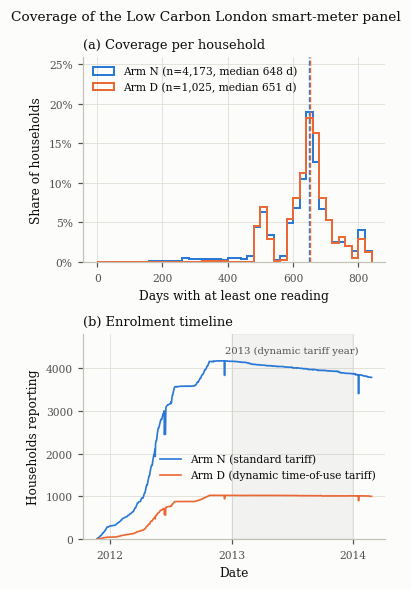

In [11]:
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.4))

    ax = axes[0]
    bins = np.arange(0, hh.n_any_days.max() + 21, 20)
    for arm in ("N", "D"):
        d = hh.loc[hh.arm == arm, "n_any_days"]
        ax.hist(d, bins=bins, weights=np.full(len(d), 1 / len(d)), histtype="step", linewidth=1.3,
                color=ARM_COLORS[arm], label=f"Arm {arm} (n={len(d):,}, median {int(d.median())} d)")
        ax.axvline(d.median(), color=ARM_COLORS[arm], linestyle="--", linewidth=0.9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
    ax.set_xlabel("Days with at least one reading")
    ax.set_ylabel("Share of households")
    ax.set_title("(a) Coverage per household", loc="left")
    ax.legend(frameon=False, loc="upper left")

    ax = axes[1]
    active = household_day.groupby(["date", "arm"]).size().unstack("arm")
    for arm in ("N", "D"):
        ax.plot(active.index, active[arm], color=ARM_COLORS[arm], linewidth=1.1, label=ARM_LABELS[arm])
    ax.axvspan(pd.Timestamp("2013-01-01"), pd.Timestamp("2014-01-01"), color=INK_MUTED, alpha=0.08)
    ax.text(pd.Timestamp("2013-07-02"), active.max().max() * 1.03, "2013 (dynamic tariff year)",
            ha="center", va="bottom", fontsize=6.5, color=INK_SECONDARY)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_ylim(0, active.max().max() * 1.15)
    ax.set_xlabel("Date")
    ax.set_ylabel("Households reporting")
    ax.set_title("(b) Enrolment timeline", loc="left")
    # Legend in the clear band between the two arms, right of the 2012 enrolment ramp.
    ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.24))

    fig.suptitle("Coverage of the Low Carbon London smart-meter panel", fontsize=9)
    fig.tight_layout()
    savefig(fig, "LCL1_coverage")
    plt.show()

### Figure LCL2 - Winter, summer and all-year load profiles, arms N and D (2013)

Mean kWh per half-hour over every reading in 2013, from households passing the quality filters.
Both panels share the y-axis, so the all-year lines also give the arm N vs arm D comparison.
In calendar 2013, winter is January, February and December.

saved -> figures/LCL2_load_profiles_arm_n_d.png


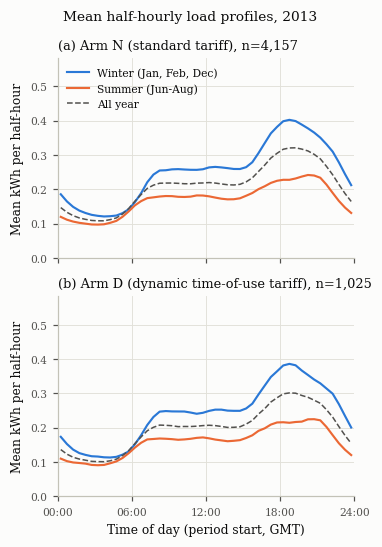

arm N: all-year peak 0.321 kWh at 19:00, winter/summer daily energy 1.48x
arm D: all-year peak 0.301 kWh at 18:30, winter/summer daily energy 1.50x


In [12]:
ok_ids = hh.loc[hh.passes_filters, ["household_id"]]
con.register("ok_ids", ok_ids)
profiles = {}
for arm in ("N", "D"):
    p = con.execute(f"""
        SELECT hh_of_day,
               avg(kwh) AS all_year,
               avg(kwh) FILTER (WHERE month IN (12, 1, 2)) AS winter,
               avg(kwh) FILTER (WHERE month IN (6, 7, 8)) AS summer
        FROM {arm.lower()}_ext JOIN ok_ids USING (household_id)
        WHERE year(date) = {ANALYSIS_YEAR}
        GROUP BY 1 ORDER BY 1
    """).fetchdf()
    p["slot"] = p.hh_of_day.str[:2].astype(int) * 2 + p.hh_of_day.str[3:5].astype(int) // 30
    profiles[arm] = p.sort_values("slot")

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.0), sharex=True, sharey=True)
    for ax, arm in zip(axes, ("N", "D")):
        p = profiles[arm]
        x = p.slot + 0.5
        ax.plot(x, p.winter, color=WINTER_COLOR, linewidth=1.4, label="Winter (Jan, Feb, Dec)")
        ax.plot(x, p.summer, color=SUMMER_COLOR, linewidth=1.4, label="Summer (Jun-Aug)")
        ax.plot(x, p.all_year, color=ALLYEAR_COLOR, linewidth=1.0, linestyle="--", label="All year")
        n = int(hh[(hh.arm == arm) & hh.passes_filters].shape[0])
        ax.set_title(f"({'a' if arm == 'N' else 'b'}) {ARM_LABELS[arm]}, n={n:,}", loc="left")
        ax.set_ylabel("Mean kWh per half-hour")
    hhmm_axis(axes[1], step_hours=6)
    axes[1].set_xlim(0, 48)
    axes[1].set_xlabel("Time of day (period start, GMT)")
    # Headroom above the evening peak so the legend sits clear of the curves.
    axes[0].set_ylim(0, max(p.winter.max() for p in profiles.values()) * 1.45)
    axes[0].legend(frameon=False, loc="upper left")
    fig.suptitle(f"Mean half-hourly load profiles, {ANALYSIS_YEAR}", fontsize=9)
    fig.tight_layout()
    savefig(fig, "LCL2_load_profiles_arm_n_d")
    plt.show()

for arm in ("N", "D"):
    p = profiles[arm]
    print(f"arm {arm}: all-year peak {p.all_year.max():.3f} kWh at {p.loc[p.all_year.idxmax(), 'hh_of_day']}, "
          f"winter/summer daily energy {p.winter.sum() / p.summer.sum():.2f}x")

### Figure LCL3 - Daily consumption, arm N (2013)

Each household's mean daily kWh over its complete days in 2013, one panel per group, stacked on a
shared x-axis. Each bar is a share of that group's households and the y-axis is shared, so groups
of very different size can be compared directly. The dashed line is the group median. The x-axis is
drawn to the 99th percentile of all arm-N households; values above it are placed in the last bin.

saved -> figures/LCL3_daily_kwh_hist_by_heating.png


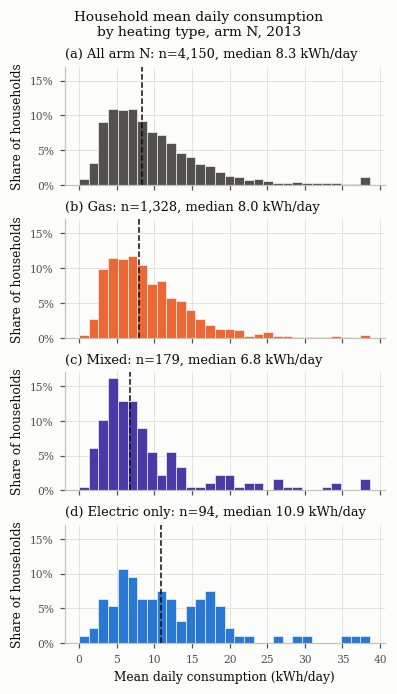

       All arm N      Gas   Mixed  Electric only
count    4150.00  1328.00  179.00          94.00
mean       10.11     9.30    9.40          12.09
std         7.57     5.79    8.09           7.66
min         0.00     0.54    1.20           0.08
25%         5.29     5.29    4.44           6.46
50%         8.33     7.98    6.83          10.92
75%        12.76    11.77   10.85          16.32
max       105.88    54.10   46.15          39.85


In [13]:
arm_n = hh[(hh.arm == "N") & hh.passes_filters & hh.mean_daily_kwh_year.notna()]
groups = {"All arm N": arm_n} | {g: arm_n[arm_n.heat_group == g] for g in HEAT_ORDER}
x_max = arm_n.mean_daily_kwh_year.quantile(0.99)
bins = np.linspace(0, x_max, 31)

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(len(groups), 1, figsize=(COL_WIDTH, 6.2), sharex=True, sharey=True,
                             layout="constrained")
    for ax, (label, df), tag in zip(axes, groups.items(), "abcd"):
        v = df.mean_daily_kwh_year
        ax.hist(v.clip(upper=x_max), bins=bins, weights=np.full(len(v), 1 / len(v)),
                color=HEAT_COLORS[label], edgecolor=SURFACE, linewidth=0.4)
        ax.axvline(v.median(), color=INK_PRIMARY, linestyle="--", linewidth=1)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
        ax.set_ylabel("Share of households")
        ax.set_title(f"({tag}) {label}: n={len(v):,}, median {v.median():.1f} kWh/day", loc="left")
    axes[-1].set_xlabel("Mean daily consumption (kWh/day)")
    fig.suptitle(f"Household mean daily consumption\nby heating type, arm N, {ANALYSIS_YEAR}", fontsize=9)
    savefig(fig, "LCL3_daily_kwh_hist_by_heating")
    plt.show()

print(pd.DataFrame({k: v.mean_daily_kwh_year.describe(percentiles=[.25, .5, .75]) for k, v in groups.items()}).round(2))

### Figure LCL4 - Winter/summer ratio, arm N (2013)

Each household's mean daily kWh in winter (January, February, December) divided by its mean in
summer (June-August). A household needs at least 15 complete days in each season and both means
above 0.05 kWh/day. One panel per group on shared axes, as a share of the group's households; the
dashed line is the group median. The x-axis is drawn to the 99th percentile; the dotted line marks
no seasonal change (ratio 1).

saved -> figures/LCL4_winter_summer_ratio_hist_by_heating.png


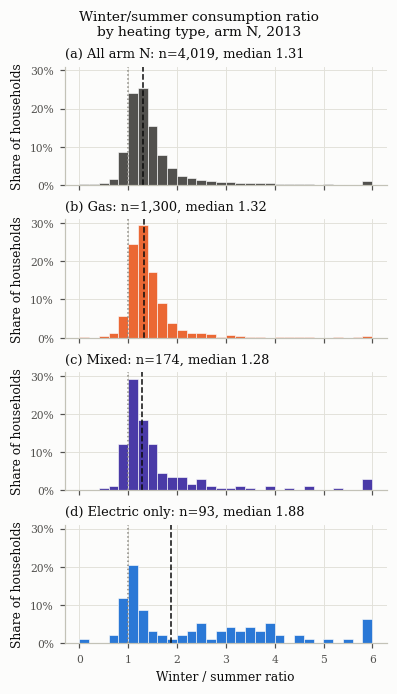

saved -> tables/LCL_S_winter_summer_ratio_by_heating.csv


,count,mean,std,min,25%,50%,75%,max
All arm N,4019.0,1.596,2.987,0.032,1.124,1.312,1.587,170.590
Gas,1300.0,1.468,0.762,0.195,1.159,1.316,1.542,11.839
Mixed,174.0,1.724,1.526,0.584,1.091,1.277,1.658,14.188
Electric only,93.0,2.582,2.393,0.063,1.112,1.884,3.504,19.321


In [14]:
ratio_n = arm_n[arm_n.winter_summer_ratio.notna()]
groups = {"All arm N": ratio_n} | {g: ratio_n[ratio_n.heat_group == g] for g in HEAT_ORDER}
x_max = ratio_n.winter_summer_ratio.quantile(0.99)
bins = np.linspace(0, x_max, 31)

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(len(groups), 1, figsize=(COL_WIDTH, 6.2), sharex=True, sharey=True,
                             layout="constrained")
    for ax, (label, df), tag in zip(axes, groups.items(), "abcd"):
        v = df.winter_summer_ratio
        ax.hist(v.clip(upper=x_max), bins=bins, weights=np.full(len(v), 1 / len(v)),
                color=HEAT_COLORS[label], edgecolor=SURFACE, linewidth=0.4)
        ax.axvline(v.median(), color=INK_PRIMARY, linestyle="--", linewidth=1)
        ax.axvline(1.0, color=INK_MUTED, linestyle=":", linewidth=1)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
        ax.set_ylabel("Share of households")
        ax.set_title(f"({tag}) {label}: n={len(v):,}, median {v.median():.2f}", loc="left")
    axes[-1].set_xlabel("Winter / summer ratio")
    fig.suptitle(f"Winter/summer consumption ratio\nby heating type, arm N, {ANALYSIS_YEAR}", fontsize=9)
    savefig(fig, "LCL4_winter_summer_ratio_hist_by_heating")
    plt.show()

# Supporting output, used by the heat-pump linkage (notebook 04).
ratio_table = pd.DataFrame({k: v.winter_summer_ratio.describe(percentiles=[.25, .5, .75]) for k, v in groups.items()}).T
savetable(ratio_table.round(3), "LCL_S_winter_summer_ratio_by_heating")

### Figure LCL5 - Monthly consumption by heating type, arm N (2013)

For each household and month, the mean daily kWh over its complete days (at least 10 in the
month). Bars show the **median household** and whiskers the **interquartile range** across
households. The median is used rather than the mean because the whiskers describe spread around
it, and daily consumption is right-skewed.

saved -> figures/LCL5_monthly_kwh_by_heating.png


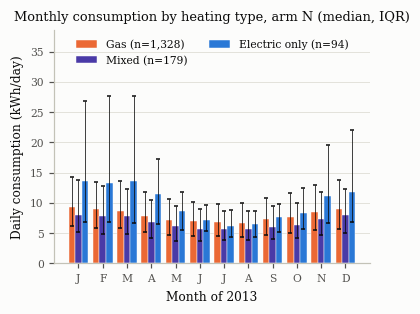

heat_group,Gas,Mixed,Electric only
month,,,
1,9.28,7.97,13.63
2,8.98,7.75,13.26
3,8.68,7.76,13.52
4,7.84,6.79,11.44
5,7.17,6.11,8.61
6,6.97,5.65,7.22
7,6.75,5.74,6.19
8,6.69,5.64,6.55
9,7.25,5.94,7.58


In [15]:
MIN_MONTH_DAYS = 10
month_hh = (year_days.merge(arm_n[["household_id", "heat_group"]], on="household_id")
            .groupby(["heat_group", "household_id", "month"])
            .agg(kwh=("total_kwh", "mean"), n=("date", "size")).reset_index())
month_hh = month_hh[month_hh.n >= MIN_MONTH_DAYS]
stats = (month_hh.groupby(["heat_group", "month"]).kwh
         .agg(q25=lambda s: s.quantile(.25), median="median", q75=lambda s: s.quantile(.75), n="size")
         .reset_index())

with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.9))
    x, width = np.arange(12), 0.27
    for i, grp in enumerate(HEAT_ORDER):
        s = stats[stats.heat_group == grp].set_index("month").reindex(range(1, 13))
        ax.bar(x + (i - 1) * width, s["median"], width, color=HEAT_COLORS[grp], edgecolor=SURFACE,
               linewidth=0.3, label=f"{grp} (n={int(s.n.max()):,})")
        ax.errorbar(x + (i - 1) * width, s["median"],
                    yerr=[s["median"] - s.q25, s.q75 - s["median"]],
                    fmt="none", ecolor=INK_PRIMARY, elinewidth=0.5, capsize=1)
    ax.set_xticks(x)
    ax.set_xticklabels([m[0] for m in MONTH_LABELS])
    ax.set_xlabel(f"Month of {ANALYSIS_YEAR}")
    ax.set_ylabel("Daily consumption (kWh/day)")
    ax.set_ylim(0, stats.q75.max() * 1.4)
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, ncol=2, loc="upper center")
    ax.set_title("Monthly consumption by heating type, arm N (median, IQR)")
    fig.tight_layout()
    savefig(fig, "LCL5_monthly_kwh_by_heating")
    plt.show()

stats.pivot(index="month", columns="heat_group", values="median")[HEAT_ORDER].round(2)

### Figure LCL6 - Heat map by heating type, arm N (2013)

Each cell is the mean kWh per half-hour across all households of that heating type, for that
month and time of day. The colour scale (0 to 1.05 kWh) is shared with the Electrification of
Heat heat map in `02_eoh_analysis` and with Figure HP_J3 of `04_hp_linkage_lcl_eoh`, the combined
household and heat-pump load, so the three can be read against each other.

Gas: max cell 0.399 kWh
Electric only: max cell 0.621 kWh
saved -> figures/LCL6_heat_map_by_heating.png


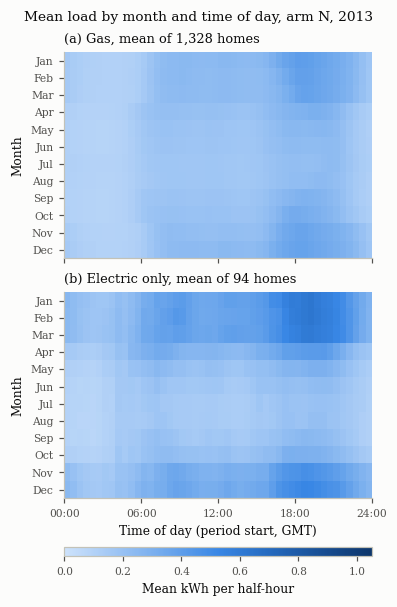

In [16]:
con.register("heat_groups", arm_n[["household_id", "heat_group"]])
gm = con.execute(f"""
    SELECT g.heat_group, e.month, e.hh_of_day, avg(e.kwh) AS mean_kwh
    FROM n_ext e JOIN heat_groups g USING (household_id)
    WHERE g.heat_group IN ('Gas', 'Electric only') AND year(e.date) = {ANALYSIS_YEAR}
    GROUP BY 1, 2, 3
""").fetchdf()
gm["slot"] = gm.hh_of_day.str[:2].astype(int) * 2 + gm.hh_of_day.str[3:5].astype(int) // 30

MAP_GROUPS = ["Gas", "Electric only"]
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.4), sharex=True, layout="constrained")
    for ax, g, tag in zip(axes, MAP_GROUPS, "ab"):
        mat = (gm[gm.heat_group == g].pivot_table(index="month", columns="slot", values="mean_kwh")
               .reindex(index=range(1, 13), columns=range(48)))
        im = ax.imshow(mat.values, aspect="auto", origin="upper", cmap=SEQ_BLUE_CMAP,
                       vmin=0, vmax=HEATMAP_VMAX, extent=[0, 48, 12, 0])
        ax.set_yticks(np.arange(12) + 0.5)
        ax.set_yticklabels(MONTH_LABELS)
        ax.set_ylabel("Month")
        n = int((arm_n.heat_group == g).sum())
        ax.set_title(f"({tag}) {g}, mean of {n:,} homes", loc="left")
        ax.grid(False)
        print(f"{g}: max cell {np.nanmax(mat.values):.3f} kWh")
    hhmm_axis(axes[1], step_hours=6)
    axes[1].set_xlabel("Time of day (period start, GMT)")
    # One horizontal colour bar under both maps.
    cbar = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.05, pad=0.02, aspect=35)
    cbar.set_label("Mean kWh per half-hour")
    fig.suptitle(f"Mean load by month and time of day, arm N, {ANALYSIS_YEAR}", fontsize=9)
    savefig(fig, "LCL6_heat_map_by_heating")
    plt.show()

## 6. Notes and limitations

- The survey's question file is off by one against the answers (section 3), so its labels can't be
  taken at face value.
- Economy 7 homes were excluded from the trial, so storage heating is largely missing and the
  electric-only group is mostly direct and panel heaters.
- Heating type is self-reported and known only for households that answered the survey. "No
  central heating" is taken to mean electric heating.
- Arm N was opt-in rather than a random sample, and arm D had the dynamic tariff only in 2013,
  which is why Figure LCL2 uses 2013 alone.
- The EV check applies the Metcalfe et al. (2026) rule unchanged. Its 7 kW threshold misses slower
  3.7 kW chargers, and the survey has no EV question, so the conclusion of no EVs rests on the
  trial's dates and the low flag rate.